# 시설 수를 늘리면 SafeNight 점수는 어떻게 달라질까?

기존 랜덤 포레스트(RF)는 같은 관측에서 시설 수만 늘렸을 때 일부 지점에 더 높은 위험점수를 매겼다. 원래 산식대로라면 시설 수가 늘 때 점수는 낮아지거나 같아야 한다. 이 차이를 줄이기 위해 2025년 10월 12일 관측 3,713행으로 점수식을 다시 구성했다.

비교 기준은 기존 환경점수를 위험 방향으로 바꾼 값 $R=100-\mathrm{safety\_index}$다. [입력 자료](data/score_research.csv) · [결과 표와 그림](../docs/notebook-results/)

In [26]:
import sys
import os
from pathlib import Path

NOTEBOOK_DIR = Path(os.environ['SAFENIGHT_NOTEBOOK_DIR']) if 'SAFENIGHT_NOTEBOOK_DIR' in os.environ else next(
    path for path in [Path.cwd(), Path.cwd()/'notebooks'] if (path/'data').is_dir()
)
assert sys.version_info >= (3,11)
print(f'Python {sys.version.split()[0]}')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.isotonic import IsotonicRegression
from scipy.optimize import lsq_linear


r_output = NOTEBOOK_DIR.parent / 'docs/notebook-results'
r_output.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'axes.grid':False,
                     'axes.spines.top':False, 'axes.spines.right':False})


Python 3.11.15


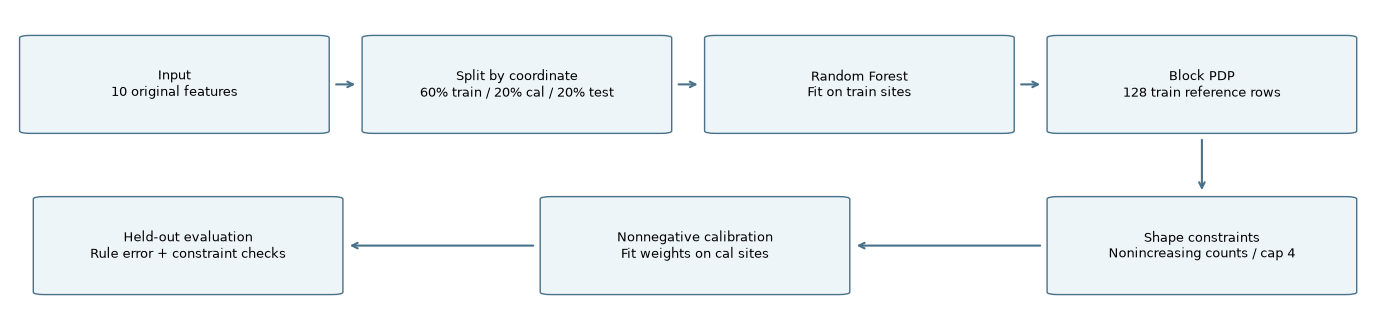

In [27]:
# 알고리즘 흐름도: 학습·보정·평가 자료의 역할을 구분한다.
r_nodes = [
    (.12,.76,"Input\n10 original features"),
    (.37,.76,"Split by coordinate\n60% train / 20% cal / 20% test"),
    (.62,.76,"Random Forest\nFit on train sites"),
    (.87,.76,"Block PDP\n128 train reference rows"),
    (.87,.24,"Shape constraints\nNonincreasing counts / cap 4"),
    (.50,.24,"Nonnegative calibration\nFit weights on cal sites"),
    (.13,.24,"Held-out evaluation\nRule error + constraint checks"),
]
r_fig,r_ax = plt.subplots(figsize=(14,3.4))
r_ax.set(xlim=(0,1),ylim=(0,1)); r_ax.axis("off")
for r_x,r_ypos,r_label in r_nodes:
    r_ax.add_patch(FancyBboxPatch((r_x-.105,r_ypos-.15),.21,.30,
                                boxstyle="round,pad=0.008",fc="#eef5f9",ec="#48718a"))
    r_ax.text(r_x,r_ypos,r_label,ha="center",va="center",fontsize=9)
for (r_x1,r_y1,_),(r_x2,r_y2,_) in zip(r_nodes,r_nodes[1:]):
    r_dx,r_dy = np.sign(r_x2-r_x1),np.sign(r_y2-r_y1)
    r_ax.annotate("",xy=(r_x2-.116*r_dx,r_y2-.17*r_dy),
                  xytext=(r_x1+.116*r_dx,r_y1+.17*r_dy),
                  arrowprops={"arrowstyle":"->","color":"#48718a","lw":1.5})
r_fig.tight_layout()
r_fig.savefig(r_output/"algorithm-flow.png",dpi=150)
display(r_fig); plt.close(r_fig)

## 학습 지점과 평가 지점

같은 지점의 관측은 한 집단에만 넣었다. 671개 지점 중 402곳으로 RF를 학습하고 134곳에서 계수를 조정했다. 나머지 135곳은 평가에 썼다. 소음 변동은 최댓값과 최솟값 차이의 4분의 1로 계산했다.

원래 분석을 재현하기 위해 입력과 점수가 중복된 583행과 위경도가 뒤바뀐 11행도 포함했다. 좌표는 집단을 나눌 때만 썼다.

In [28]:
r_raw = pd.read_csv(NOTEBOOK_DIR/"data/score_research.csv")
r_features = ["조도 최대(lux)","조도 평균(lux)","조도 최소(lux)","소음 최대(dB)",
              "소음 평균(dB)","소음 최소(dB)","소음_Std","CCTV_개수_25m","가로등_개수_25m","보안등_개수_25m"]
r_X = r_raw[r_features].astype(float)
r_y = 100-pd.to_numeric(r_raw["safety_index"]).to_numpy()
assert np.isfinite(r_X).all().all() and r_X.ge(0).all().all()
assert np.isfinite(r_y).all() and np.all((0 <= r_y) & (r_y <= 50))
assert r_raw[["위도","경도"]].notna().all().all()
assert (r_X.iloc[:,5] <= r_X.iloc[:,4]).all() and (r_X.iloc[:,4] <= r_X.iloc[:,3]).all()
np.testing.assert_allclose(r_X.iloc[:,6],(r_X.iloc[:,3]-r_X.iloc[:,5])/4)

def r_rule_risk(frame):
    noise = frame["소음 평균(dB)"].to_numpy()
    light = np.clip(100-frame["조도 평균(lux)"].to_numpy()/3,0,100)
    noise_risk = np.where(noise<40,np.clip(100-2.5*noise,0,100),
                         np.where(noise<=70,(noise-40)*20/30,np.minimum(100,20+(noise-70)*2)))
    traffic = np.where(noise==0,50,np.clip(50-100*frame["소음_Std"].to_numpy()/(noise+1e-5),0,100))
    protection = (.25*np.minimum(100,25*frame[r_features[7]].to_numpy())
                  +.15*np.minimum(100,20*frame[r_features[8]].to_numpy())
                  +.05*np.minimum(100,30*frame[r_features[9]].to_numpy()))
    return np.clip(.30*light+.15*noise_risk+.10*traffic-protection,0,50)

np.testing.assert_allclose(r_rule_risk(r_X),r_y,atol=1e-8,rtol=0)
r_quality = {
    "rows": len(r_raw), "input_columns": len(r_features),
    "missing_input_target": int(r_raw[r_features + ["safety_index"]].isna().sum().sum()),
    "duplicate_input_target": int(r_raw.duplicated(subset=r_features + ["safety_index"]).sum()),
    "invalid_coordinate_rows": int((~r_raw["위도"].between(-90,90) | ~r_raw["경도"].between(-180,180)).sum()),
}
print(r_quality)
r_groups = pd.factorize(pd.MultiIndex.from_frame(r_raw[["위도","경도"]]))[0]
r_trainval,r_test = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=42).split(r_X,groups=r_groups))
r_a,r_b = next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=43)
              .split(r_X.iloc[r_trainval],groups=r_groups[r_trainval]))
r_train,r_cal = r_trainval[r_a],r_trainval[r_b]
assert all(set(r_groups[a]).isdisjoint(r_groups[b])
           for a,b in [(r_train,r_cal),(r_train,r_test),(r_cal,r_test)])
r_weights = 1/pd.Series(r_groups).map(pd.Series(r_groups).value_counts()).to_numpy()
r_forest = RandomForestRegressor(n_estimators=114,max_depth=18,min_samples_split=2,
                                min_samples_leaf=1,max_features=None,bootstrap=True,random_state=42)
r_forest.fit(r_X.iloc[r_train],100-r_y[r_train])
r_rf_risk = 100-r_forest.predict(r_X)
display(pd.DataFrame([{"split":name,"rows":len(idx),"sites":len(np.unique(r_groups[idx]))}
                      for name,idx in [("Train",r_train),("Calibration",r_cal),("Test",r_test)]]))

{'rows': 3713, 'input_columns': 10, 'missing_input_target': 0, 'duplicate_input_target': 583, 'invalid_coordinate_rows': 11}


,split,rows,sites
0,Train,2230,402
1,Calibration,740,134
2,Test,743,135


## 조도·소음·시설별 점수 곡선

학습 지점 128곳에서 관측을 하나씩 뽑았다. 한 입력을 바꿔 가며 이 관측들의 평균 예측값을 구하면 RF가 그 입력에 어떻게 반응하는지 볼 수 있다. 이 곡선이 부분 의존도(PDP)다.

먼저 열 개 변수를 하나씩 바꿨다. 다음에는 한 관측의 조도 세 값과 소음 네 값을 각각 한 묶음으로 바꿨다. 이렇게 하면 최솟값·평균·최댓값의 순서가 유지된다. 시설 곡선은 학습 자료로 구해 시설 수가 늘수록 위험점수가 낮아지거나 같도록 맞췄다. 원래 산식에 따라 CCTV와 보안등은 네 개부터 같은 값으로 뒀다.

In [29]:
r_blocks = [r_features[:3],r_features[3:7],[r_features[7]],[r_features[8]],[r_features[9]]]
r_block_names = ["Light","Noise","CCTV","Streetlight","Security light"]
r_rng = np.random.default_rng(42)
r_order = r_rng.permutation(np.unique(r_groups[r_train]))
r_reference_rows = [r_rng.choice(np.flatnonzero(r_groups==group)) for group in r_order]
r_reference = r_X.iloc[r_reference_rows[:128]]
r_mu = float((100-r_forest.predict(r_reference)).mean())

def r_pdp(frame,columns):
    unique = frame[columns].drop_duplicates().reset_index(drop=True)
    mixed = np.tile(r_reference.to_numpy(),(len(unique),1))
    mixed[:,[r_features.index(c) for c in columns]] = np.repeat(unique.to_numpy(),len(r_reference),axis=0)
    values = (100-r_forest.predict(pd.DataFrame(mixed,columns=r_features))).reshape(-1,len(r_reference)).mean(axis=1)
    lookup = pd.Series(values,index=pd.MultiIndex.from_frame(unique))
    return lookup.reindex(pd.MultiIndex.from_frame(frame[columns])).to_numpy()

r_single_pd = {feature:r_pdp(r_X,[feature]) for feature in r_features}
r_single_matrix = np.column_stack(list(r_single_pd.values()))
r_single_matrix -= r_single_matrix[r_reference.index].mean(axis=0)
r_block_pd = np.column_stack([r_pdp(r_X,cols) if len(cols)>1 else r_single_pd[cols[0]] for cols in r_blocks])
r_centers = r_block_pd[r_reference.index].mean(axis=0)
r_block_matrix = r_block_pd-r_centers
r_shape_matrix = r_block_matrix.copy()
r_shape_models = {}
for r_j,r_cap in [(2,4),(3,np.inf),(4,4)]:
    r_feature = r_blocks[r_j][0]
    r_curve = pd.DataFrame({"count":r_X.iloc[r_train][r_feature],
                            "pdp":r_block_pd[r_train,r_j]}).drop_duplicates().sort_values("count")
    r_iso = IsotonicRegression(increasing=False,out_of_bounds="clip")
    r_iso.fit(np.minimum(r_curve["count"],r_cap),r_curve["pdp"])
    r_values = r_iso.predict(np.minimum(r_X[r_feature],r_cap))
    r_center = float(r_values[r_reference.index].mean())
    r_shape_matrix[:,r_j] = r_values-r_center
    r_shape_models[r_j] = (r_iso,r_cap,r_center)
np.testing.assert_allclose(r_shape_matrix[r_reference.index].mean(axis=0),0,atol=1e-10)
print("PDP 5개 블록 생성 · 시설 단조·포화 제약 적용 완료")

PDP 5개 블록 생성 · 시설 단조·포화 제약 적용 완료


## 다섯 곡선을 한 점수로 결합

$$
R_{\mathrm{new}}(x)
= \operatorname{clip}_{[0,50]}\!\left[
  \alpha + \sum_{B} w_B\,\widetilde{P}_B(x_B)
\right],
\qquad w_B \ge 0
$$

관측 $x$에서 조도·소음·CCTV·가로등·보안등 묶음별 기여분 $\widetilde{P}_B(x_B)$을 구했다. 보정 지점마다 같은 비중을 주고, 원래 점수와의 오차가 가장 작아지는 절편 $\alpha$와 가중치 $w_B$를 찾았다. 보정 자료에는 가로등이 기록된 지점이 없어 가로등 가중치는 1로 고정했다.

In [30]:
r_free = np.ptp(r_shape_matrix[r_cal],axis=0)>1e-10
r_design = np.column_stack([np.ones(len(r_cal)),r_shape_matrix[r_cal][:,r_free]])
r_fixed = r_shape_matrix[r_cal][:,~r_free].sum(axis=1)
r_sqrt_w = np.sqrt(r_weights[r_cal])
r_fit = lsq_linear(r_design*r_sqrt_w[:,None],(r_y[r_cal]-r_fixed)*r_sqrt_w,
                  bounds=(np.r_[-np.inf,np.zeros(r_free.sum())],np.full(r_free.sum()+1,np.inf)),
                  tol=1e-12,max_iter=500)
assert r_fit.success
r_alpha,r_coef = float(r_fit.x[0]),np.ones(len(r_blocks))
r_coef[r_free] = r_fit.x[1:]
r_new_raw = r_alpha+r_shape_matrix@r_coef
assert np.sum(r_weights[r_cal]*(r_new_raw[r_cal]-r_y[r_cal])**2) <= (
       np.sum(r_weights[r_cal]*(r_mu+r_shape_matrix[r_cal].sum(axis=1)-r_y[r_cal])**2)+1e-8)

def r_predict_new(frame):
    values = frame[r_features].astype(float)
    assert np.isfinite(values).all().all() and values.ge(0).all().all()
    components = []
    for j,columns in enumerate(r_blocks):
        if j < 2:
            components.append(r_pdp(values,columns)-r_centers[j])
        else:
            iso,cap,center = r_shape_models[j]
            components.append(iso.predict(np.minimum(values[columns[0]],cap))-center)
    return np.clip(r_alpha+np.column_stack(components)@r_coef,0,50)

np.testing.assert_allclose(r_predict_new(r_X.iloc[r_test]),np.clip(r_new_raw[r_test],0,50),atol=1e-10)
display(pd.Series([r_alpha,*r_coef],index=["Intercept",*r_block_names],name="Final coefficient").round(5))

Intercept         20.53824
Light              1.56809
Noise              1.00665
CCTV               0.99702
Streetlight        1.00000
Security light     1.09376
Name: Final coefficient, dtype: float64

## 평가 지점에서 오차와 역전 횟수 비교

평가 지점 135곳의 관측 743행에서 원래 산식과의 오차(MAE·RMSE)를 계산했다. 관측이 많은 지점에 결과가 치우치지 않도록 지점별 비중을 같게 뒀다.

각 행의 다른 입력은 그대로 두고 시설 수만 자료에서 관측된 다음 개수로 늘렸다. 이때 위험점수가 $10^{-6}$점 넘게 오르면 역전 한 건으로 셌다.

In [31]:
r_predictions = {name:np.clip(value,0,50) for name,value in {
    "Original RF":r_rf_risk,
    "Single PDP sum":r_mu+r_single_matrix.sum(axis=1),
    "Block PDP sum":r_mu+r_block_matrix.sum(axis=1),
    "Shape constraints":r_mu+r_shape_matrix.sum(axis=1),
    "Final score":r_new_raw}.items()}
r_metrics = pd.DataFrame([
    {"Method":name,"MAE":np.average(np.abs(pred[r_test]-r_y[r_test]),weights=r_weights[r_test]),
     "RMSE":np.sqrt(np.average((pred[r_test]-r_y[r_test])**2,weights=r_weights[r_test]))}
    for name,pred in r_predictions.items()]).set_index("Method")
r_checks = []
for r_j in [2,3,4]:
    r_feature = r_blocks[r_j][0]
    r_grid = np.sort(r_X[r_feature].unique())
    r_sweep = pd.concat([r_X.iloc[r_test].assign(**{r_feature:value}) for value in r_grid],ignore_index=True)
    r_rf_sweep = (100-r_forest.predict(r_sweep)).reshape(len(r_grid),-1)
    r_iso,r_cap,r_center = r_shape_models[r_j]
    r_effect = r_iso.predict(np.minimum(r_grid,r_cap))-r_center
    r_new_sweep = r_new_raw[r_test][None,:]+r_coef[r_j]*(r_effect[:,None]-r_shape_matrix[r_test,r_j])
    for r_name,r_values in [("Original RF",r_rf_sweep),("Final score",r_new_sweep)]:
        r_values = np.clip(r_values,0,50)
        r_diff = np.diff(r_values,axis=0)
        r_after_cap = r_values[r_grid>=r_cap]
        r_checks.append({"Method":r_name,"Comparisons":r_diff.size,"Reversals":int((r_diff>1e-6).sum()),
                         "Max increase":float(np.maximum(r_diff,0).max()),
                         "Post-cap change":float(np.abs(r_after_cap-r_after_cap[:1]).max()) if len(r_after_cap) else 0})
r_constraints = pd.DataFrame(r_checks).groupby("Method",sort=False).agg(
    {"Comparisons":"sum","Reversals":"sum","Max increase":"max","Post-cap change":"max"})
assert r_constraints.loc["Final score","Reversals"] == 0
assert r_constraints.loc["Final score","Post-cap change"] < 1e-10
r_metrics.to_csv(r_output/"results.csv")
r_constraints.to_csv(r_output/"constraints.csv")
display(r_metrics.round(5))
display(r_constraints.round(5))

,MAE,RMSE
Method,,
Original RF,0.66540,1.24978
Single PDP sum,0.72107,1.22238
Block PDP sum,0.47227,0.86169
Shape constraints,0.46873,0.86087
Final score,0.40250,0.80255


,Comparisons,Reversals,Max increase,Post-cap change
Method,,,,
Original RF,17089,1263,1.47366,1.10168
Final score,17089,0,0.00000,0.00000


## CCTV와 보안등을 함께 늘렸을 때

기준 관측 128행에서 CCTV와 보안등 수를 각각 0~5개로 바꾸고, 조합마다 평균 위험점수를 구했다.

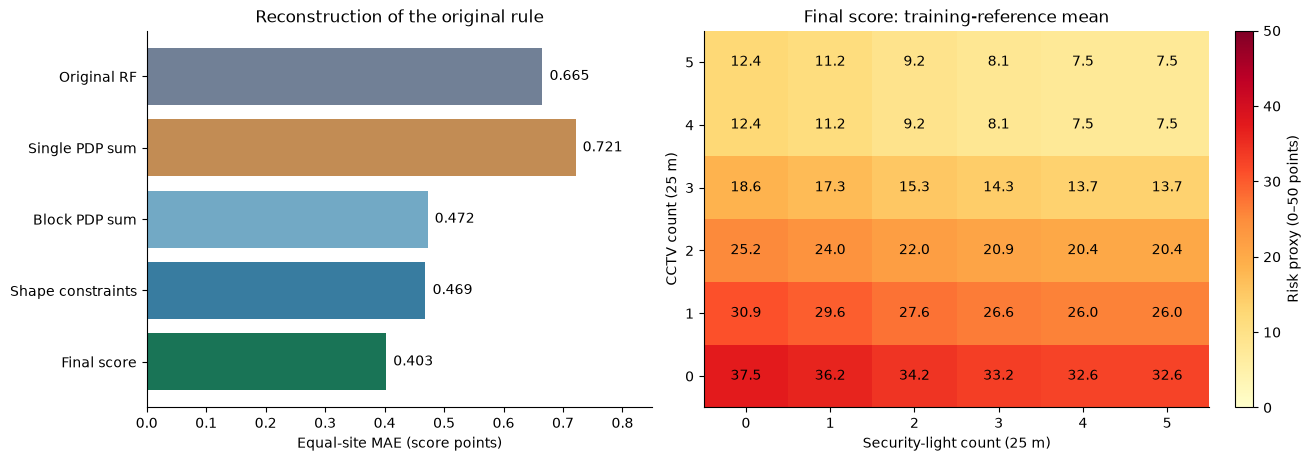

MAE 감소 39.5% · 시설 역전 1,263 → 0건
개선은 블록화·형태 제약·별도 계수 보정을 합친 결과입니다.


In [32]:
r_count_grid = np.arange(6,dtype=float)
r_heat_frame = pd.concat([r_reference.assign(**{r_features[7]:c,r_features[9]:b})
                         for c in r_count_grid for b in r_count_grid],ignore_index=True)
r_heat = r_predict_new(r_heat_frame).reshape(6,6,len(r_reference)).mean(axis=2)
r_fig,r_axes = plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
r_axes[0].barh(r_metrics.index,r_metrics["MAE"],color=["#718096","#c28c54","#72a9c5","#387ca0","#197456"])
r_axes[0].invert_yaxis()
r_axes[0].set(xlim=(0,.85),xlabel="Equal-site MAE (score points)",title="Reconstruction of the original rule")
for r_i,r_value in enumerate(r_metrics["MAE"]):
    r_axes[0].text(r_value+.012,r_i,f"{r_value:.3f}",va="center")
r_img = r_axes[1].imshow(r_heat,cmap="YlOrRd",vmin=0,vmax=50,origin="lower",aspect="auto")
r_axes[1].set(xticks=range(6),yticks=range(6),xlabel="Security-light count (25 m)",
              ylabel="CCTV count (25 m)",title="Final score: training-reference mean")
for r_i,r_j in np.ndindex(r_heat.shape):
    r_axes[1].text(r_j,r_i,f"{r_heat[r_i,r_j]:.1f}",ha="center",va="center")
r_fig.colorbar(r_img,ax=r_axes[1],label="Risk proxy (0–50 points)")
r_fig.savefig(r_output/"core-results.png",dpi=160)
display(r_fig); plt.close(r_fig)
r_reduction = 100*(1-r_metrics.loc["Final score","MAE"]/r_metrics.loc["Original RF","MAE"])
print(f"MAE 감소 {r_reduction:.1f}% · 시설 역전 {r_constraints.loc['Original RF','Reversals']:,} → 0건")
print("개선은 블록화·형태 제약·별도 계수 보정을 합친 결과입니다.")

## 결과

변수별 PDP를 더했을 때 MAE는 기존 RF의 0.6654점에서 0.7211점으로 커졌다. 조도와 소음을 각각 묶자 0.4723점으로 줄었다. 시설 곡선을 원래 산식의 방향에 맞추고 계수를 조정한 최종값은 0.4025점이었다. 기존 RF보다 오차가 39.5% 작았다.

시설 수를 늘린 17,089쌍에서 위험점수가 오른 경우는 1,263건에서 0건으로 줄었다. 이 수치는 하루치 자료에서 원래 환경점수를 얼마나 일관되게 재현했는지 보여 준다. 실제 보행 안전과의 관계는 별도 검증이 필요하다.

[PDP 방법](https://doi.org/10.1214/aos/1013203451) · [서로 연관된 변수의 해석](https://arxiv.org/abs/1612.08468)